# 04 Comparison: the same 2 questions in MongoDB, Neo4j and SQLite

| | |
|---|---|
| **Question** | How do MongoDB, Neo4j and SQL compare on 'top contested pages' and 'mutual reverts' (spec section 5): same result, lines of code, time and modeling pain? |
| **Answer** | All 3 engines give identical results (<!--fact:cmp_all_identical-->yes<!--/fact-->). Mutual reverts: Cypher <!--fact:cmp_loc_mutual_neo4j-->6<!--/fact--> lines (<!--fact:cmp_chars_mutual_neo4j-->275<!--/fact--> characters), SQL <!--fact:cmp_loc_mutual_sqlite-->13<!--/fact--> (<!--fact:cmp_chars_mutual_sqlite-->412<!--/fact-->), MongoDB <!--fact:cmp_loc_mutual_mongodb-->52<!--/fact--> (<!--fact:cmp_chars_mutual_mongodb-->884<!--/fact-->); <!--fact:cmp_bracket_lines_mutual_mongodb-->18<!--/fact--> of the MongoDB lines hold only brackets. Timing label: <!--fact:cmp_timing_label-->`draft`<!--/fact--> (a `draft` time is PROVISIONAL). Modeling-pain scores: <!--fact:cmp_pain_scored_by-->draft by Claude Code; Comparison+viz owner to re-score<!--/fact-->. |
| **Time to run** | about 10 seconds |
| **Needs** | the local MongoDB and Neo4j (Docker) and `data/tables/truthlag.sqlite`. Without the databases, sections 1, 3, 4 and 5 still work (they read `results/`). |

Human editors appear only as pseudonyms (`editor_` + 10 hex digits). Bots keep their names. All data times are UTC. Words: see `GLOSSARY.md`. Numbers: see `report/FACTS.md`. Every number in the text comes from there (`report/sync_notebook_text.py` copies it).

## Setup

**What:** Finds the project folder, imports `config.py` and the report helpers, and prints the data version.

**Why:** Every rule and path comes from `config.py`. The data version tells you which data release you have.

**You should see:** `DATA_VERSION: data-v1` (or a later version) and the path of the Python program.

In [1]:
# Set up the paths: this notebook is in ec-hw2/notebooks/, the project code is in ec-hw2/.
import sys, time, json
from pathlib import Path
HW2 = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd() / "ec-hw2"
sys.path.insert(0, str(HW2))
import config
import pandas as pd
from tabulate import tabulate
from IPython.display import Image, Markdown, display
from report import build_facts as facts      # FACTS.md helpers (check, tables with pseudonyms)
from report import make_figures as figs      # the report charts
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
T0 = time.time()

def _cell(v):
    if v is None or v is pd.NA or (isinstance(v, float) and v != v):
        return ""
    if isinstance(v, float):
        return f"{v:,.1f}" if abs(v) >= 1000 else f"{v:.4g}"
    return v

def show(df, n=None):
    """Print a table as text (it reads well on GitHub). Each cell keeps its own type."""
    d = df if n is None else df.head(n)
    rows = [[_cell(v) for v in r] for r in d.astype(object).itertuples(index=False)]
    print(tabulate(rows, headers=list(d.columns), tablefmt="github"))

print("DATA_VERSION:", config.DATA_VERSION)
print("Python:", sys.executable)

DATA_VERSION: data-v1
Python: /Users/scottnelson/Desktop/226/truth-lag/.venv/bin/python3


## 1. results/comparison.md

**What:** Shows `results/comparison.md`, made by `comparison/compare.py`.

**Why:** It is the main evidence for 'Comparison top 5': the table, the modeling pain, the candidate findings and how we measured.

**You should see:** The comparison page with its tables, the timing label at the top, and the machine details.

In [2]:
display(Markdown((config.RESULTS_DIR / "comparison.md").read_text()))

# Three-engine comparison: MongoDB, Neo4j and SQLite

**Timing label: draft.** Load average (1 / 5 / 15 min): 3.45 / 3.55 / 3.14 at the start and 3.46 / 3.55 / 3.14 at the end. Other jobs may have been running. `--final` runs only when the 1-minute load average is at most 2.0. The equality checks and the query sizes do not depend on the timing.

Made by `ec-hw2/comparison/compare.py` on 2026-10-24 09:56 UTC (data-v1). Full tables: `comparison.csv` (the 6 compared rows) and `comparison_extra.csv` (the extra row). Both questions use the history cohort and the shared definitions in `DATA_MODEL.md` section 7.

## Results

| question | engine | lines of code | code characters | median ms | min-max ms | same result? | modeling note |
|---|---|---:|---:|---:|---:|---|---|
| top contested pages | MongoDB | 62 | 1,040 | 76.7 | 72.5-100.5 | yes | 12 stages: group the links per page and keep pages with 2+ reverted editors; then a $lookup into revisions counts the human edits of the 1,357 kept pages only. |
| top contested pages | Neo4j | 18 | 768 | 114.2 | 107.9-142.0 | yes | Two MATCH steps: the first filters all 295,013 EDITED relationships on the revert flags (there is no separate revert-link table), the second counts the edits of the 1,357 kept pages only. |
| top contested pages | SQLite | 38 | 1,224 | 25.2 | 24.7-30.8 | yes | GROUP BY with HAVING, then one correlated COUNT per kept page (the 1,357 kept pages); the score is 1.0 * a / b to avoid whole-number division. |
| mutual reverts | MongoDB | 52 | 884 | 133.1 | 128.4-158.0 | yes | The reverse direction needs a self-$lookup with let and $expr, run once per a < b triple (4,229 times). |
| mutual reverts | Neo4j | 6 | 275 | 39.3 | 30.7-45.2 | yes | The pattern (a)-[:REVERTED]->(b)-[:REVERTED]->(a) is one line, but it needs page_id on all 13,269 REVERTED relationships. |
| mutual reverts | SQLite | 13 | 412 | 16.1 | 15.9-16.7 | yes | A CTE of (reverter, author, page) triples is joined to itself with the roles swapped. |
| mutual reverts | SQLite, pre-aggregated input (extra row, not compared) | 5 | 188 | 1.4 | 1.4-1.6 | yes (same rows as the SQLite raw-link query) | The same self-join as the SQLite query, on the pre-aggregated TEMP table. |

**Speed.** We call an engine faster only when its min-max range does not overlap the other engine's range.

- top contested pages: MongoDB is faster than Neo4j (72.5-100.5 ms vs 107.9-142.0 ms; the ranges do not overlap).
- top contested pages: SQLite is faster than MongoDB (24.7-30.8 ms vs 72.5-100.5 ms; the ranges do not overlap).
- top contested pages: SQLite is faster than Neo4j (24.7-30.8 ms vs 107.9-142.0 ms; the ranges do not overlap).
- mutual reverts: Neo4j is faster than MongoDB (30.7-45.2 ms vs 128.4-158.0 ms; the ranges do not overlap).
- mutual reverts: SQLite is faster than MongoDB (15.9-16.7 ms vs 128.4-158.0 ms; the ranges do not overlap).
- mutual reverts: SQLite is faster than Neo4j (15.9-16.7 ms vs 30.7-45.2 ms; the ranges do not overlap).
- mutual reverts, extra row: SQLite, pre-aggregated input is faster than Neo4j (1.4-1.6 ms vs 30.7-45.2 ms; the ranges do not overlap).

## What each timed query reads

- **Neo4j, mutual reverts:** Reads the REVERTED relationships that export_graph.py pre-aggregated (one per reverter, reverted editor and page, with count); that grouping is NOT inside the timed query. In MongoDB, the export_graph.py step that builds these relationships took 0.09 s (from `_SUCCESS_export_graph.json`). MongoDB and SQLite do this grouping inside the timed query, so the Neo4j time is not like for like.
- **Extra row:** `queries/sql/compare_mutual_reverts_preaggregated.sql` gives SQLite the same head start. It builds the grouped triples once as a TEMP table in memory (12.5 ms, not timed; 15 lines of setup code), then times only the self-join. Its result is compared with the SQLite raw-link result: yes (same rows as the SQLite raw-link query).
- **MongoDB:** revert_links holds 37,117 documents (19,858 history, 17,259 live) and revisions holds 574,482 documents (295,016 history). Both pipelines start with $match cohort = 'history', so the live documents are filtered out inside the timed query.
  - top contested pages: query plan of the first $match: IXSCAN on index cohort_1_page_id_1, 19,858 documents examined; median 75.9 ms with this default plan and 70.5 ms with a forced collection scan (hint {$natural: 1}, 7 runs each, helper runs).
  - mutual reverts: query plan of the first $match: IXSCAN on index cohort_1_page_id_1, 19,858 documents examined; median 127.5 ms with this default plan and 129.9 ms with a forced collection scan (hint {$natural: 1}, 7 runs each, helper runs).
- **SQLite and Neo4j** hold the history cohort only.

## Modeling pain (1 = easy, 5 = hard)

Scored by: draft by Claude Code; Comparison+viz owner to re-score. The scores and reasons come from `comparison/pain.csv`. They are not the team's judgment until the Comparison+viz owner re-scores them in that file and writes their name in scored_by.

| question | engine | pain | reason | scored by |
|---|---|---:|---|---|
| top contested pages | MongoDB | 3 | Two collections: a $lookup sub-pipeline counts the human edits, and each distinct count needs $addToSet and then $size. | draft by Claude Code; Comparison+viz owner to re-score |
| top contested pages | Neo4j | 3 | The revert facts are on the EDITED relationships only because the export copied them there; the query needs two MATCH steps and a CASE inside count(). | draft by Claude Code; Comparison+viz owner to re-score |
| top contested pages | SQLite | 2 | Plain GROUP BY with HAVING and a correlated COUNT, but a plain join made SQLite scan all revisions, and the float division (1.0 * a / b) needs care. | draft by Claude Code; Comparison+viz owner to re-score |
| mutual reverts | MongoDB | 4 | The longest query: a self-$lookup with let variables, and its inner $match repeats the outer filter. | draft by Claude Code; Comparison+viz owner to re-score |
| mutual reverts | Neo4j | 2 | The query is short, but the loader first had to build one REVERTED relationship per editor pair and page. | draft by Claude Code; Comparison+viz owner to re-score |
| mutual reverts | SQLite | 2 | Short, but the swapped join condition (r.a = f.b AND r.b = f.a) is easy to get wrong. | draft by Claude Code; Comparison+viz owner to re-score |

## Candidate findings for 'Comparison top 5'

Facts with numbers only. The Comparison+viz owner turns them into findings in their own words.

- Top contested pages: the outputs are identical in MongoDB, Neo4j and SQLite (20 rows, in order, scores to 6 digits). Rank 1 is page 11383948 (Personality_and_image_of_Elizabeth_II): 13 revert actions / 14 human edits = 0.928571.
- Top contested pages, step 1 keeps 1,357 pages with 2+ reverted editors; all 3 engines count the human edits for these pages only.
- 5 of the top 20 pages share a score with another page (scores 0.714286, 0.600000). The tie order uses revert_actions, then edits, then page_id, in all 3 engines.
- Mutual reverts: the outputs are identical in the 3 engines: 462 pairs on 397 pages, with 631 distinct editors; 25 pairs include a bot.
- 18 of the top 20 contested pages have at least one mutual pair; together they hold 51 of the 462 pairs.
- Query size (code characters without spaces / lines of code): top contested pages: MongoDB 1,040 characters / 62 lines, Neo4j 768 characters / 18 lines, SQLite 1,224 characters / 38 lines; mutual reverts: MongoDB 884 characters / 52 lines, Neo4j 275 characters / 6 lines, SQLite 412 characters / 13 lines. Line counts depend on the layout: 40 of the 114 MongoDB lines hold only brackets or commas.
- Median time in ms with the min-max range (draft, 1 warm-up, then 3 rounds of 7 timed runs (21 runs per query)): top contested pages: MongoDB 76.7 (72.5-100.5), Neo4j 114.2 (107.9-142.0), SQLite 25.2 (24.7-30.8); mutual reverts: MongoDB 133.1 (128.4-158.0), Neo4j 39.3 (30.7-45.2), SQLite 16.1 (15.9-16.7).
- Speed, top contested pages: MongoDB is faster than Neo4j (72.5-100.5 ms vs 107.9-142.0 ms; the ranges do not overlap). SQLite is faster than MongoDB (24.7-30.8 ms vs 72.5-100.5 ms; the ranges do not overlap). SQLite is faster than Neo4j (24.7-30.8 ms vs 107.9-142.0 ms; the ranges do not overlap).
- Speed, mutual reverts: Neo4j is faster than MongoDB (30.7-45.2 ms vs 128.4-158.0 ms; the ranges do not overlap). SQLite is faster than MongoDB (15.9-16.7 ms vs 128.4-158.0 ms; the ranges do not overlap). SQLite is faster than Neo4j (15.9-16.7 ms vs 30.7-45.2 ms; the ranges do not overlap).
- Mutual reverts on pre-aggregated input (extra row): SQLite takes 1.4 ms (1.4-1.6) when it reads triples grouped beforehand, against 16.1 ms (15.9-16.7) on the raw revert links; Neo4j, which reads the REVERTED relationships grouped by export_graph.py, takes 39.3 ms (30.7-45.2). Building the TEMP table took 12.5 ms (not timed).
- Input sizes: SQLite revert_links has 19,858 rows (17,868 pass within_followup and by_other), which make 13,269 (reverter, author, page) triples; 4,229 of them have a < b, so the MongoDB self-$lookup runs 4,229 times. MongoDB revert_links has 37,117 documents (19,858 history). Neo4j has 13,269 REVERTED relationships and 295,013 EDITED relationships.
- MongoDB first $match (cohort = 'history'): top contested pages: IXSCAN cohort_1_page_id_1, 19,858 documents examined, median 75.9 ms with the default plan (the index exists) vs 70.5 ms with a forced collection scan; mutual reverts: IXSCAN cohort_1_page_id_1, 19,858 documents examined, median 127.5 ms with the default plan (the index exists) vs 129.9 ms with a forced collection scan.
- 3 history revisions have no editor key (pages 87880, 20197943, 84167596). SQLite and MongoDB count them as human edits; Neo4j has no EDITED relationship for them. None of these pages is in the top 20.

## How we measured

1. **Same result?** We compare the full ordered list. Top contested pages: (page_id, score rounded to 6 digits), as `config.py` says. We also compare edits, revert_actions, reverted_editors and contested, and the 3 top-contested queries must return the same columns. No query computes a rank: `run_mongo.py`, `run_cypher.py` and `run_sql.py` add it in Python, so it is not timed in any engine. Mutual reverts: (page_id, a, b, a_reverted_b, b_reverted_a). Neo4j shows aliases, so we turn them back into editor keys with the graph's own key/alias map. "yes" means equal to both other engines.
2. **Time.** 1 warm-up, then 3 rounds of 7 timed runs (21 runs per query). The engines take turns, and the order changes after every run. The time runs in Python from sending the query until every row is in memory, so it includes the network hop and decoding for MongoDB and Neo4j. We report the median and the min-max range of all timed runs; `comparison.csv` also has the median of each round (round_medians_ms). We call an engine faster only when the ranges do not overlap. This file and `comparison.csv` are the one timing source for the comparison; the times in the `results/mongo_*`, `cypher_*` and `sql_*` files are single-engine runs, not for the comparison.
3. **Query size.** Lines of code are non-blank lines that are not comments; code characters are the characters without spaces. MongoDB: the "pipeline" array in the JSON file, as `run_mongo.py` writes it. Neo4j: the "main" statement only (Cypher Q1 also has a "total" statement, which is not counted). SQLite: the whole statement, with its params block. Line counts depend on the layout (the CSV column bracket_only_lines counts lines with only brackets or commas), so read both numbers together.
4. **Where the engines run.** MongoDB and Neo4j run in Docker in a Colima VM. SQLite runs inside the Python process on the host, with no network hop. So the times compare whole setups, not only the database engines.
5. **Modeling pain** is a draft until the owner re-scores it (see above). The numbers in the modeling notes come from this run.

## Machine

| item | value |
|---|---|
| macOS | 27.0.1 (arm64) |
| CPU (host) | Apple M5, 10 cores (4 performance + 6 efficiency) |
| RAM (host) | 16.0 GiB |
| Colima VM (MongoDB + Neo4j) | 4 CPUs, 5.8 GiB RAM, Ubuntu 24.04.4 LTS |
| MongoDB container memory limit | 1.5 GiB |
| Neo4j container memory limit | 3.0 GiB |
| MongoDB version | 8.0.34 |
| MongoDB WiredTiger cache | 1.0 GiB |
| Neo4j version | 2026.10.1 community |
| Neo4j memory | heap 1.46GiB, page cache 1.00GiB |
| SQLite version | 3.53.1 (in the Python process on the host) |
| Python and drivers | Python 3.12.13, pymongo 4.19.0, neo4j driver 6.4.1 |
| load average (1 / 5 / 15 min), start | 3.45 / 3.55 / 3.14 |
| load average (1 / 5 / 15 min), end | 3.46 / 3.55 / 3.14 |
| --final load threshold (1 min) | 2.0 |

## Query files

- top contested pages: MongoDB `queries/mongo/q2_top_contested_pages.json`, Neo4j `queries/cypher/compare_top_contested.cypher`, SQLite `queries/sql/compare_top_contested.sql`
- mutual reverts: MongoDB `queries/mongo/compare_mutual_reverts.json`, Neo4j `queries/cypher/q1_mutual_reverts.cypher`, SQLite `queries/sql/compare_mutual_reverts.sql`
- extra row: `queries/sql/compare_mutual_reverts_preaggregated.sql`


## 2. The equality checks (run now)

**What:** Runs the 6 queries once each (2 questions x 3 engines) with the engine code of `comparison/compare.py`, and checks that the outputs are identical (the full ordered list; scores rounded to 6 digits).

**Why:** The comparison is only fair if the 3 engines answer exactly the same question.

**You should see:** 6 rows: <!--fact:cmp_rows_top_mongodb-->20<!--/fact--> rows for top contested pages and <!--fact:cmp_rows_mutual_mongodb-->462<!--/fact--> for mutual reverts in every engine, and `yes` in the 'same result' column.

In [3]:
from comparison import compare
queries = compare.load_queries()
eng = compare.Engines()
print("engines not reachable:", eng.errors or "none")
check_rows, run_ms = [], {}
for qn in compare.QUESTIONS:
    runners = {e: eng.runner(queries[(qn, e)]) for e in compare.ENGINES if e not in eng.errors}
    out = compare.measure(runners, runs=1)
    norm = {}
    for e, o in out.items():
        if o["rows"] is None:
            continue
        rows = o["rows"]
        norm[e] = compare.norm_top(rows) if qn == compare.TOP else compare.norm_mutual(
            rows, eng.alias_to_key() if e == "Neo4j" else None)
        run_ms[(qn, e)] = round(o["times"][0], 1)
    same = compare.same_result(qn, norm)
    for e in compare.ENGINES:
        check_rows.append({"question": qn, "engine": e, "rows": len(norm[e]["key"]) if e in norm else None,
                           "same result": same[e]["text"], "1 run here (ms)": run_ms.get((qn, e))})
eng.close()
eq = pd.DataFrame(check_rows)
show(eq)
all_same = bool((eq["same result"] == "yes").all())
print("\nall identical:", "yes" if all_same else "NO")

engines not reachable: none


| question            | engine   |   rows | same result   |   1 run here (ms) |
|---------------------|----------|--------|---------------|-------------------|
| top contested pages | MongoDB  |     20 | yes           |             147.2 |
| top contested pages | Neo4j    |     20 | yes           |             147.3 |
| top contested pages | SQLite   |     20 | yes           |             394.4 |
| mutual reverts      | MongoDB  |    462 | yes           |             126.1 |
| mutual reverts      | Neo4j    |    462 | yes           |              32.7 |
| mutual reverts      | SQLite   |    462 | yes           |              21.5 |

all identical: yes


## 3. Timings (draft or final) and lines of code

**What:** Shows the timings of `results/comparison.csv`: the median, the fastest and the slowest of <!--fact:cmp_runs_per_query-->21<!--/fact--> runs per query (<!--fact:cmp_rounds-->3<!--/fact--> rounds; the engines take turns), the timing label and `faster_than`. It also counts the lines of code again from the query files (`compare.py` rules: non-blank, non-comment lines), next to the characters of code and the lines that hold only brackets. Then it shows the extra row of `results/comparison_extra.csv` and the input note of each engine.

**Why:** We call an engine faster only when its min-max range does not overlap with the range of the other engine (`faster_than`). Draft timings were measured while other jobs ran (1-minute load average at the start: <!--fact:cmp_load_average_start-->3.45<!--/fact-->). The report must use the final timings (`compare.py --final` on an idle Mac). Lines of code depend on the layout, so we also give characters. The Neo4j time for mutual reverts does not include the grouping: `export_graph.py` built the REVERTED relationships before the timing (see the input notes).

**You should see:** The timing label from comparison.csv (now <!--fact:cmp_timing_label-->`draft`<!--/fact-->), and 'lines of code (recount)' equal to the CSV. Median (fastest-slowest) in ms:
- top contested pages: MongoDB <!--fact:cmp_ms_top_mongodb-->76.7<!--/fact--> (<!--fact:cmp_ms_min_top_mongodb-->72.5<!--/fact-->-<!--fact:cmp_ms_max_top_mongodb-->100.5<!--/fact-->), Neo4j <!--fact:cmp_ms_top_neo4j-->114.2<!--/fact--> (<!--fact:cmp_ms_min_top_neo4j-->107.9<!--/fact-->-<!--fact:cmp_ms_max_top_neo4j-->142.0<!--/fact-->), SQLite <!--fact:cmp_ms_top_sqlite-->25.2<!--/fact--> (<!--fact:cmp_ms_min_top_sqlite-->24.7<!--/fact-->-<!--fact:cmp_ms_max_top_sqlite-->30.8<!--/fact-->).
- mutual reverts: MongoDB <!--fact:cmp_ms_mutual_mongodb-->133.1<!--/fact--> (<!--fact:cmp_ms_min_mutual_mongodb-->128.4<!--/fact-->-<!--fact:cmp_ms_max_mutual_mongodb-->158.0<!--/fact-->), Neo4j <!--fact:cmp_ms_mutual_neo4j-->39.3<!--/fact--> (<!--fact:cmp_ms_min_mutual_neo4j-->30.7<!--/fact-->-<!--fact:cmp_ms_max_mutual_neo4j-->45.2<!--/fact-->), SQLite <!--fact:cmp_ms_mutual_sqlite-->16.1<!--/fact--> (<!--fact:cmp_ms_min_mutual_sqlite-->15.9<!--/fact-->-<!--fact:cmp_ms_max_mutual_sqlite-->16.7<!--/fact-->).
- Top contested pages, faster when the min-max ranges do not overlap. MongoDB is faster than: <!--fact:cmp_faster_than_top_mongodb-->Neo4j<!--/fact-->. Neo4j is faster than: <!--fact:cmp_faster_than_top_neo4j-->none<!--/fact-->. SQLite is faster than: <!--fact:cmp_faster_than_top_sqlite-->MongoDB; Neo4j<!--/fact-->.
- Mutual reverts, faster when the min-max ranges do not overlap. MongoDB is faster than: <!--fact:cmp_faster_than_mutual_mongodb-->none<!--/fact-->. Neo4j is faster than: <!--fact:cmp_faster_than_mutual_neo4j-->MongoDB<!--/fact-->. SQLite is faster than: <!--fact:cmp_faster_than_mutual_sqlite-->MongoDB; Neo4j<!--/fact-->.
- The extra row (SQLite on a pre-aggregated TEMP table, like the REVERTED relationships of Neo4j): <!--fact:cmp_ms_mutual_sqlite_preagg-->1.4<!--/fact--> ms (<!--fact:cmp_ms_min_mutual_sqlite_preagg-->1.4<!--/fact-->-<!--fact:cmp_ms_max_mutual_sqlite_preagg-->1.6<!--/fact-->). It is not compared, because its grouping is done before the timing.

In [4]:
cmp = pd.read_csv(config.RESULTS_DIR / "comparison.csv")
cmp["lines of code (recount)"] = [len(queries[(q, e)]["code"]) for q, e in zip(cmp["question"], cmp["engine"])]
show(cmp[["timing_label", "question", "engine", "lines_of_code", "lines of code (recount)", "code_chars",
          "bracket_only_lines", "median_ms", "min_ms", "max_ms", "runs", "faster_than", "result_rows", "same_result"]])
extra = pd.read_csv(config.RESULTS_DIR / "comparison_extra.csv")
print("\nExtra row (not compared; results/comparison_extra.csv):")
show(extra[["question", "engine", "lines_of_code", "code_chars", "setup_ms", "median_ms", "min_ms", "max_ms",
            "runs", "same_result"]])
print("\nInput notes:")
for _, r in cmp.iterrows():
    print(f"- {r['question']} / {r['engine']}: {r['input_note']}")
label = cmp["timing_label"].iloc[0]
print(f"\ntiming label: {label}" + ("  -> re-run 'compare.py --final' on an idle Mac before the report uses these times"
                                   if label == "draft" else ""))

| timing_label   | question            | engine   |   lines_of_code |   lines of code (recount) |   code_chars |   bracket_only_lines |   median_ms |   min_ms |   max_ms |   runs | faster_than    |   result_rows | same_result   |
|----------------|---------------------|----------|-----------------|---------------------------|--------------|----------------------|-------------|----------|----------|--------|----------------|---------------|---------------|
| draft          | top contested pages | MongoDB  |              62 |                        62 |         1040 |                   22 |        76.7 |     72.5 |    100.5 |     21 | Neo4j          |            20 | yes           |
| draft          | top contested pages | Neo4j    |              18 |                        18 |          768 |                    0 |       114.2 |    107.9 |    142   |     21 |                |            20 | yes           |
| draft          | top contested pages | SQLite   |              38 |           

## 4. Modeling notes

**What:** Shows the modeling note, the modeling pain score (1 = easy, 5 = hard), its reason and who scored it, for each engine and question. Then it draws the comparison figure.

**Why:** 'Comparison top 5' should say why a query was easy or hard. The scores in `comparison/pain.csv` start as drafts by Claude Code. The Comparison+viz owner re-scores them from their own experience and writes their name in `scored_by`. Until then, the `cmp_pain_*` facts are PROVISIONAL.

**You should see:** 6 rows, scored by: <!--fact:cmp_pain_scored_by-->draft by Claude Code; Comparison+viz owner to re-score<!--/fact-->. Scores now: top contested pages MongoDB <!--fact:cmp_pain_top_mongodb-->3<!--/fact-->, Neo4j <!--fact:cmp_pain_top_neo4j-->3<!--/fact-->, SQLite <!--fact:cmp_pain_top_sqlite-->2<!--/fact-->; mutual reverts MongoDB <!--fact:cmp_pain_mutual_mongodb-->4<!--/fact-->, Neo4j <!--fact:cmp_pain_mutual_neo4j-->2<!--/fact-->, SQLite <!--fact:cmp_pain_mutual_sqlite-->2<!--/fact-->. Then the figure: lines of code, characters of code, and the median time with its min-max range.

- top contested pages / MongoDB (pain 3 of 5; scored by: draft by Claude Code; Comparison+viz owner to re-score): 12 stages: group the links per page and keep pages with 2+ reverted editors; then a $lookup into revisions counts the human edits of the 1,357 kept pages only. Reason for the score: Two collections: a $lookup sub-pipeline counts the human edits, and each distinct count needs $addToSet and then $size.
- top contested pages / Neo4j (pain 3 of 5; scored by: draft by Claude Code; Comparison+viz owner to re-score): Two MATCH steps: the first filters all 295,013 EDITED relationships on the revert flags (there is no separate revert-link table), the second counts the edits of the 1,357 kept pages only. Reason for the score: The revert facts are on the EDITED relationships only because the export copied them there; the query needs two MATCH steps and a CASE inside count().
- top contested pages / SQLite (pain 2 of 5; scored by: draft by Claude Code; Comparison+viz owner to re-score)

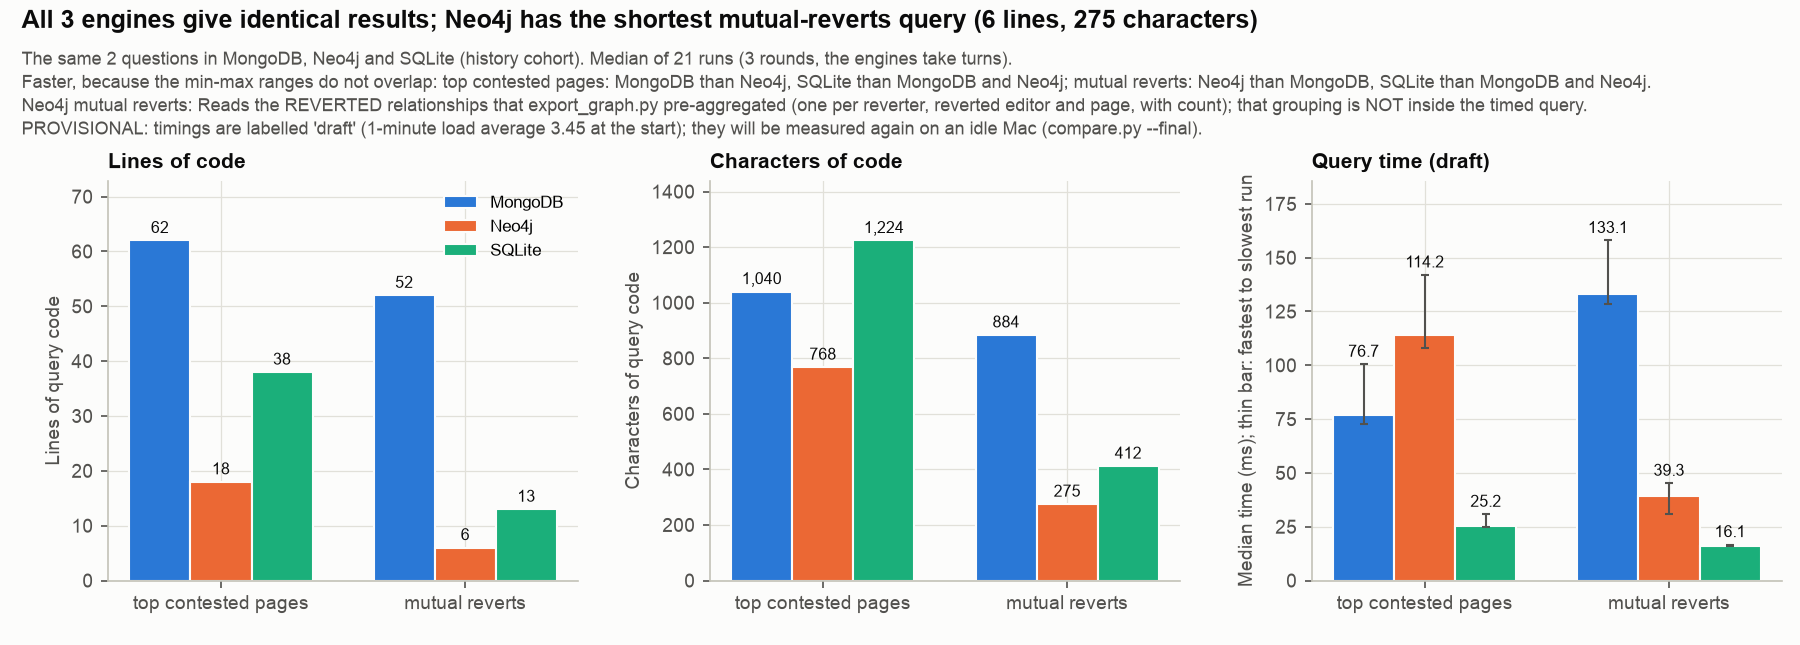

In [5]:
for _, r in cmp.iterrows():
    print(f"- {r['question']} / {r['engine']} (pain {r['modeling_pain']} of 5; scored by: {r['pain_scored_by']}): "
          f"{r['modeling_note']} "
          f"Reason for the score: {r['pain_reason']}")
display(Image(filename=str(figs.comparison_figure(cmp))))

## 5. The sharding distribution

**What:** Shows the sharding demo results (`results/sharding.md`, made by `scaleout/demo_sharding.py`): how the shard key `{"page.id": "hashed"}` spread the history cohort over 2 shards, and which queries go to one shard.

**Why:** The scale-out part of spec section 3. The Atlas free tier cannot shard, so a local 2-shard cluster shows it.

**You should see:** <!--fact:shard_shard1rs_docs-->147,462<!--/fact--> and <!--fact:shard_shard2rs_docs-->147,554<!--/fact--> documents (<!--fact:shard_shard1rs_pct-->49.98<!--/fact-->% / <!--fact:shard_shard2rs_pct-->50.02<!--/fact-->%); one page = <!--fact:shard_route_one_page-->`SINGLE_SHARD`<!--/fact-->, one editor = <!--fact:shard_route_one_editor-->`SHARD_MERGE`<!--/fact-->; <!--fact:shard_checks_ok-->12 of 12<!--/fact--> checks OK.

In [6]:
sh = json.loads((config.RESULTS_DIR / "_SUCCESS_sharding.json").read_text())
rows = sh["rows"]
dist = pd.DataFrame([{"shard": s, "documents": rows[f"documents_{s}"],
                      "share %": round(100 * rows[f"documents_{s}"] / rows["documents_copied"], 2)}
                     for s in ("shard1rs", "shard2rs")])
show(dist)
print()
show(pd.DataFrame([{"query": k, "routing": v} for k, v in sh["routing"].items()]))
print(f"\nchecks: {sum(c['ok'] for c in sh['checks'])} of {len(sh['checks'])} OK")

| shard    |   documents |   share % |
|----------|-------------|-----------|
| shard1rs |      147462 |     49.98 |
| shard2rs |      147554 |     50.02 |

| query                                | routing                       |
|--------------------------------------|-------------------------------|
| history of one page                  | SINGLE_SHARD                  |
| all edits of one editor              | SHARD_MERGE                   |
| a range of page ids                  | SHARD_MERGE                   |
| revert rate by hour of day           | both shards, merged by mongos |
| the 20 pages with the most revisions | both shards, merged by mongos |

checks: 12 of 12 OK


## Check against FACTS.md

**What:** Compares the key numbers of this notebook with `report/FACTS.md`. Then it checks every number in the text of this notebook (the fact markers) against FACTS.md.

**Why:** The report uses FACTS.md. If a number here is different, the data or the code changed: tell the Report+GenAI owner before you copy any number.

**You should see:** Two tables with one row per number, and the lines `OK: all ... numbers match FACTS.md` and `OK: all ... numbers in the text match FACTS.md`. `DIFFERENT` means a number changed (normal for PROVISIONAL numbers after the live refresh). Then run `report/build_facts.py` and `report/sync_notebook_text.py` again.

In [7]:
qk = {"top contested pages": "top", "mutual reverts": "mutual"}
check = {"cmp_all_identical": "yes" if all_same else "no", "cmp_timing_label": label,
         "shard_shard1rs_pct": dist.iloc[0]["share %"], "shard_shard2rs_pct": dist.iloc[1]["share %"],
         "shard_route_one_page": sh["routing"]["history of one page"]}
for _, r in cmp.iterrows():
    k = f"{qk[r['question']]}_{r['engine'].lower()}"
    check[f"cmp_loc_{k}"] = r["lines of code (recount)"]
    check[f"cmp_ms_{k}"] = r["median_ms"]
    check[f"cmp_ms_min_{k}"] = r["min_ms"]
    check[f"cmp_ms_max_{k}"] = r["max_ms"]
    check[f"cmp_chars_{k}"] = r["code_chars"]
    check[f"cmp_faster_than_{k}"] = r["faster_than"] if isinstance(r["faster_than"], str) and r["faster_than"] else "none"
    check[f"cmp_pain_{k}"] = r["modeling_pain"]
for _, r in eq.iterrows():
    if r["rows"] is not None:
        check[f"cmp_rows_{qk[r['question']]}_{r['engine'].lower()}"] = r["rows"]
check["cmp_runs_per_query"] = int(cmp["runs"].iloc[0])
check["shard_checks_ok"] = f"{sum(c['ok'] for c in sh['checks'])} of {len(sh['checks'])}"
facts.check(check)
print()
from report import sync_notebook_text
sync_notebook_text.check_markers(HW2 / "notebooks" / "04_comparison.ipynb")
print(f"\nnotebook time: {time.time() - T0:.0f} s")

| key                            | FACTS.md       | notebook       | status      | result   |
|--------------------------------|----------------|----------------|-------------|----------|
| cmp_all_identical              | yes            | yes            | FINAL       | OK       |
| cmp_timing_label               | draft          | draft          | PROVISIONAL | OK       |
| shard_shard1rs_pct             | 49.98          | 49.98          | FINAL       | OK       |
| shard_shard2rs_pct             | 50.02          | 50.02          | FINAL       | OK       |
| shard_route_one_page           | SINGLE_SHARD   | SINGLE_SHARD   | FINAL       | OK       |
| cmp_loc_top_mongodb            | 62             | 62             | FINAL       | OK       |
| cmp_ms_top_mongodb             | 76.7           | 76.7           | PROVISIONAL | OK       |
| cmp_ms_min_top_mongodb         | 72.5           | 72.5           | PROVISIONAL | OK       |
| cmp_ms_max_top_mongodb         | 100.5          | 100.5   

Numbers in the text of 04_comparison.ipynb (fact markers):
| cell   | key                              | text                                                   | FACTS.md                                               | result   |
|--------|----------------------------------|--------------------------------------------------------|--------------------------------------------------------|----------|
| 0      | cmp_all_identical                | yes                                                    | yes                                                    | OK       |
| 0      | cmp_loc_mutual_neo4j             | 6                                                      | 6                                                      | OK       |
| 0      | cmp_chars_mutual_neo4j           | 275                                                    | 275                                                    | OK       |
| 0      | cmp_loc_mutual_sqlite            | 13                                      